In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Split data and preprocess features
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Classification model
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the Portuguese student performance dataset
df = pd.read_csv("student-por.csv", sep=";")


# Check dataset dimensions
print("\nDataset shape:", df.shape)




Dataset shape: (649, 33)


In [4]:
# Inspect column types and non-null counts
df.info()

# Check missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Ensure final grades are numeric
df["G3"] = pd.to_numeric(df["G3"], errors="coerce")

# Remove records without a valid target
df = df.dropna(subset=["G3"]).copy()

# Check final grade range and statistics
print("\nFinal grade statistics:")
print(df["G3"].describe())

print("\nCleaned dataset shape:", df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

In [5]:
# Pass = grade of 10 or above
# Fail = grade below 10

df["Pass"] = (df["G3"] >= 10).astype(int)

print(df[["G3", "Pass"]].head(10))

print("\nPass/fail counts:")
print(df["Pass"].value_counts().rename(
    index={0: "Fail", 1: "Pass"}
))

print("\nPass/fail percentages:")
print(
    (df["Pass"].value_counts(normalize=True) * 100)
    .rename(index={0: "Fail", 1: "Pass"})
    .round(2)
)

   G3  Pass
0  11     1
1  11     1
2  12     1
3  14     1
4  13     1
5  13     1
6  13     1
7  13     1
8  17     1
9  13     1

Pass/fail counts:
Pass
Pass    549
Fail    100
Name: count, dtype: int64

Pass/fail percentages:
Pass
Pass    84.59
Fail    15.41
Name: proportion, dtype: float64


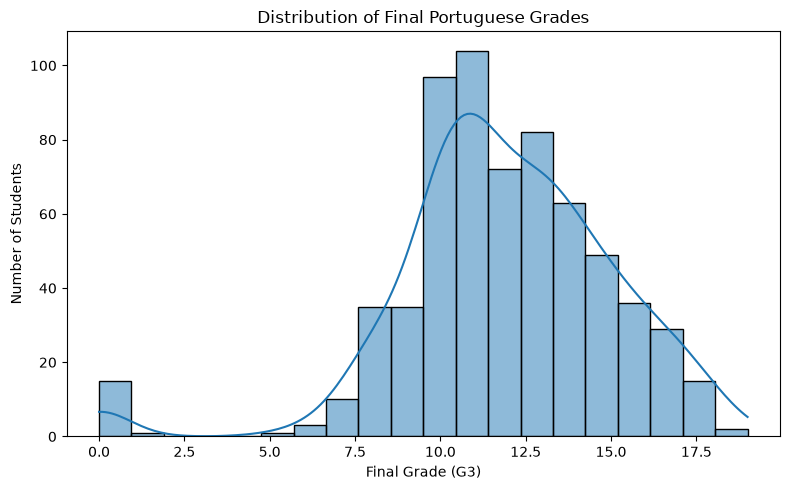

In [6]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="G3", bins=20, kde=True)

plt.title("Distribution of Final Portuguese Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

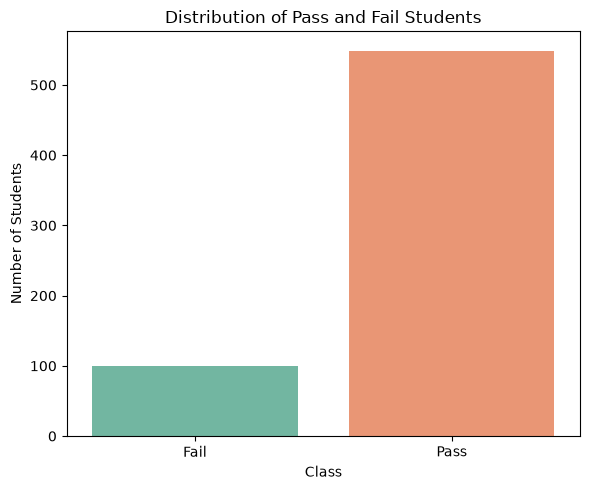

In [7]:
plt.figure(figsize=(6, 5))

sns.countplot(
    data=df,
    x="Pass",
    hue="Pass",
    order=[0, 1],
    palette="Set2",
    legend=False
)

plt.xticks([0, 1], ["Fail", "Pass"])
plt.title("Distribution of Pass and Fail Students")
plt.xlabel("Class")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

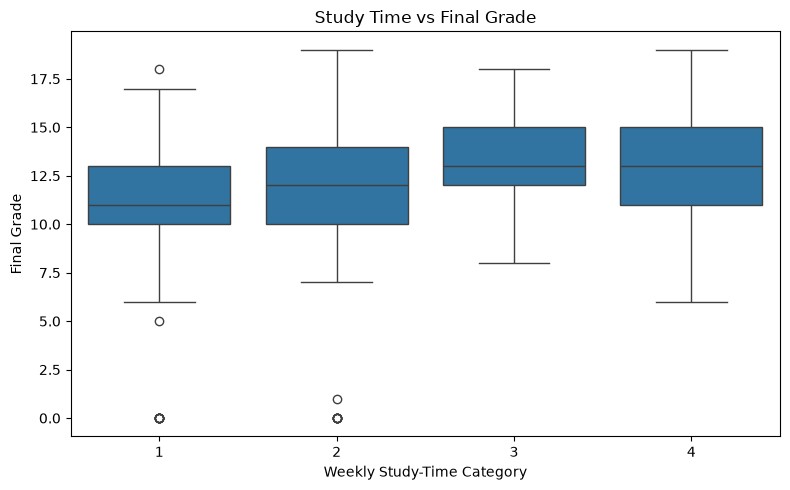

In [8]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="studytime",
    y="G3"
)

plt.title("Study Time vs Final Grade")
plt.xlabel("Weekly Study-Time Category")
plt.ylabel("Final Grade")
plt.tight_layout()
plt.show()

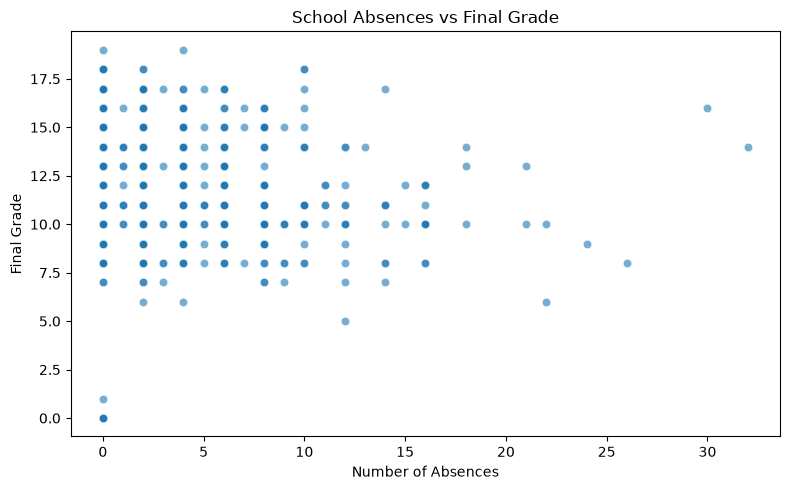

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="absences",
    y="G3",
    alpha=0.6
)

plt.title("School Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade")
plt.tight_layout()
plt.show()

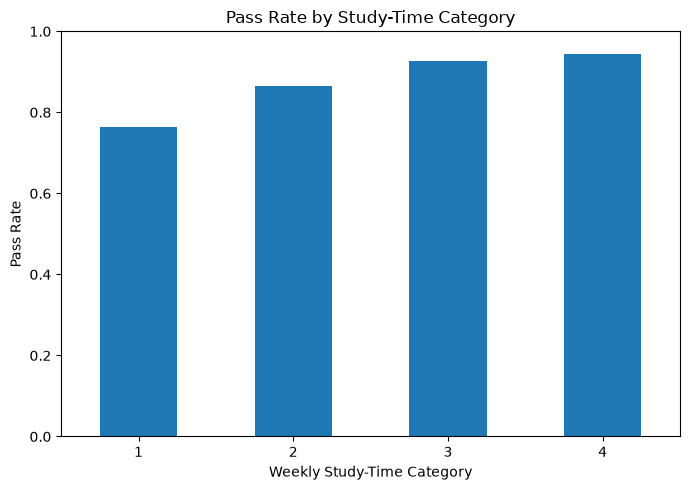

In [10]:
pass_rate = df.groupby("studytime")["Pass"].mean()

plt.figure(figsize=(7, 5))

pass_rate.plot(kind="bar")

plt.title("Pass Rate by Study-Time Category")
plt.xlabel("Weekly Study-Time Category")
plt.ylabel("Pass Rate")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
# Target: pass or fail
y = df["Pass"]

# Exclude final grade and derived target
# Exclude G1 and G2 for early prediction
X = df.drop(columns=["G3", "G1", "G2", "Pass"])

print("Input data shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

Input data shape: (649, 30)
Target shape: (649,)

Input features:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training samples: 519
Testing samples: 130

Training class proportions:
Pass
1    0.846
0    0.154
Name: proportion, dtype: float64

Testing class proportions:
Pass
1    0.846
0    0.154
Name: proportion, dtype: float64


In [14]:
# Identify feature types from training data
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["str", "object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)


# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


# Combine both transformations
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("\nPreprocessing pipeline created.")

Numerical features: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Categorical features: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Preprocessing pipeline created.


In [15]:
# Create a complete classification pipeline
logistic_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [16]:
# Predict class labels
y_pred = logistic_model.predict(X_test)

# Predict probabilities of passing
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Display a sample of predictions
prediction_results = pd.DataFrame({
    "Actual": y_test.map({0: "Fail", 1: "Pass"}).to_numpy(),
    "Predicted": pd.Series(y_pred).map(
        {0: "Fail", 1: "Pass"}
    ).to_numpy(),
    "Probability_of_Pass": y_prob
})

print(prediction_results.head(10).round(3))

  Actual Predicted  Probability_of_Pass
0   Pass      Pass                0.957
1   Pass      Pass                0.958
2   Pass      Pass                0.940
3   Pass      Pass                0.858
4   Pass      Fail                0.054
5   Fail      Fail                0.365
6   Fail      Fail                0.371
7   Pass      Pass                0.982
8   Pass      Pass                0.895
9   Pass      Pass                0.782


In [17]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

roc_auc = roc_auc_score(y_test, y_prob)

print("LOGISTIC REGRESSION - TEST RESULTS")
print("----------------------------------")
print(f"Accuracy : {accuracy:.3f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1-score : {f1:.3f}")
print(f"ROC-AUC  : {roc_auc:.3f}")

LOGISTIC REGRESSION - TEST RESULTS
----------------------------------
Accuracy : 0.792 (79.23%)
Precision: 0.867
Recall   : 0.891
F1-score : 0.879
ROC-AUC  : 0.623


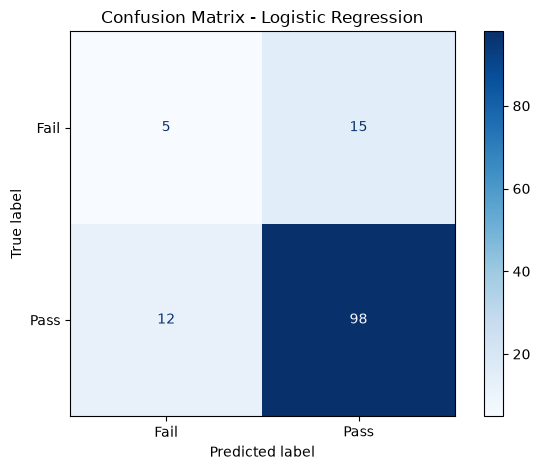


Classification report:
              precision    recall  f1-score   support

        Fail       0.29      0.25      0.27        20
        Pass       0.87      0.89      0.88       110

    accuracy                           0.79       130
   macro avg       0.58      0.57      0.57       130
weighted avg       0.78      0.79      0.79       130



In [18]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fail", "Pass"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Fail", "Pass"],
        zero_division=0
    )
)

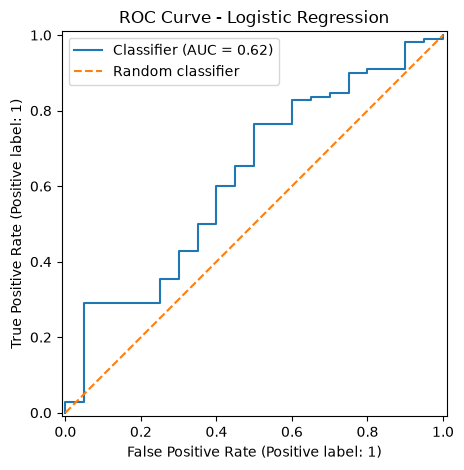

In [19]:
RocCurveDisplay.from_predictions(y_test, y_prob)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
# Create a simple baseline classifier
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

y_pred_baseline = baseline.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test, y_pred_baseline
)

print(f"Baseline accuracy: {baseline_accuracy:.3f}")
print(f"Logistic Regression accuracy: {accuracy:.3f}")

print(
    "\nImprovement in accuracy (percentage points):",
    round((accuracy - baseline_accuracy) * 100, 2)
)

Baseline accuracy: 0.846
Logistic Regression accuracy: 0.792

Improvement in accuracy (percentage points): -5.38


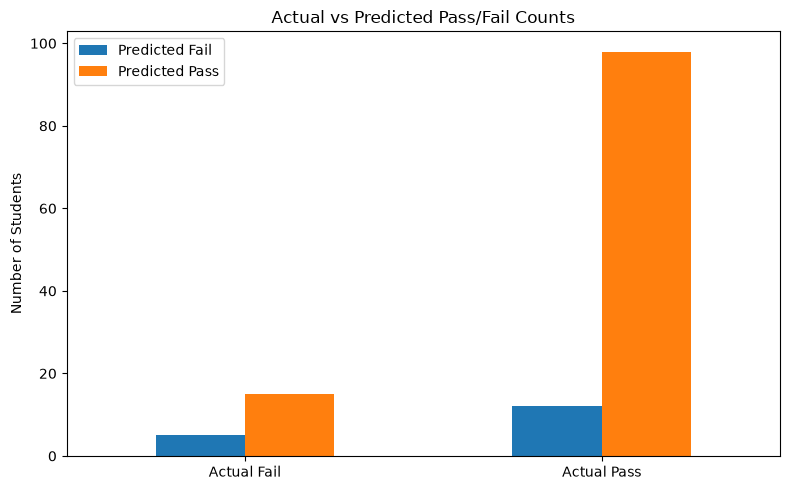

In [21]:
comparison = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

comparison_counts = pd.crosstab(
    comparison["Actual"],
    comparison["Predicted"],
    rownames=["Actual"],
    colnames=["Predicted"]
)

comparison_counts.index = ["Actual Fail", "Actual Pass"]
comparison_counts.columns = ["Predicted Fail", "Predicted Pass"]

comparison_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Actual vs Predicted Pass/Fail Counts")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()